# 08 · Anatomía de los picos: cuándo ocurren, de qué tipo son y qué los rodea

## Pregunta y alcance

El objetivo del proyecto es anticipar cuándo sube la demanda de triage. Los cuadernos 06 y 07 separaron dos capas: el **nivel**, que lo mueve la red de salud (Nueva EPS), y los **picos**, lo que se sale del nivel reciente y que mueven otras cosas. Los picos son la parte difícil del problema: a nivel de día ninguna fuente externa los anticipa de forma estable (cuaderno 14), y en los modelos de pronóstico es justamente lo que hasta ahora no se logra anticipar. Este cuaderno describe qué son, cuándo caen y qué los rodea, con las hipótesis fijadas por escrito antes de medir:

1. **Tipos de pico.** Días puntuales frente a semanas altas sostenidas.
2. **Diciembre.** Velitas, Navidad, 31 y Año Nuevo: alcohol, riñas y pólvora.
3. **La temporada de fin de año, día por día**, con la Feria y el Carnaval de Riosucio encima.
4. **Las fiestas de los pueblos.** Si lo que el hospital del pueblo no atiende termina en Manizales.
5. **La mitad de año**, con las vacaciones escolares oficiales.
6. **Los 30 picos notables, uno a uno**, con su fecha, su factor, su subgrupo y su hora, y qué parte de la demanda sube en ellos.

## De dónde salen los datos

| Dato | Archivo | Fuente |
|---|---|---|
| Triage diario, por hora, edad y asegurador del SES | `salidas/triage_*.parquet` | base del hospital, agregada (`extraccion/`) |
| Festivos y calendario | `calendarios/calendario_Colombia.csv` | calendario oficial de Colombia |
| Fiestas de 26 municipios de Caldas | `calendarios/fiestas_caldas_2020_2026.csv` | alcaldías, Gobernación, Cultura de Caldas y prensa; una URL por registro |
| Eventos de Manizales (Feria) | `calendarios/eventos_manizales_2020_2026.csv` | calendario manual con fuente |
| Lesiones personales por día (Policía) | `calendarios/seguridad_mindefensa.csv.gz` | MinDefensa, datos.gov.co |
| Lesiones por pólvora (evento 452) y consultas por IRA | `calendarios/vigilancia_sivigila*.csv.gz` | microdatos SIVIGILA, INS |
| Vacaciones escolares de mitad de año | resoluciones de la Secretaría de Educación de Manizales | `calendarios/docs/` (informe de contexto de los picos), §3 |
| Balances oficiales de pólvora, alertas y alumbrado | `calendarios/docs/` (informe de contexto de los picos) | DTSC, Gobernación y Alcaldía |

## Un límite que conviene tener presente

El triage cuenta **lo que el hospital recibe**, no lo que la ciudad necesita. En días de saturación (el SES llegó al 200 % en marzo de 2025 y hubo alerta hospitalaria en julio de 2025) el conteo puede quedarse corto justo cuando la demanda es mayor, de modo que un pico observado es una cota inferior del pico real.

In [1]:
import sys, pathlib, warnings
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ)); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from matplotlib import pyplot as plt
from extraccion.entidades import clasificar

AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
    "legend.frameon": False})
FIN, INI = "2026-09-20", "2022-03-01"
COVID = ("2020-03-15", "2022-02-28")
dias = pd.date_range("2020-01-01", FIN)
pct = lambda x: (np.exp(x) - 1) * 100

tri = pd.read_parquet(RAIZ / "salidas/triage_diario.parquet").assign(dia=lambda d: pd.to_datetime(d.dia))
tri = tri.set_index("dia")["triages"].reindex(dias).astype(float)
tri["2024-03-21"] = np.nan                          # caida parcial del registro (cuaderno 01)
hor = pd.read_parquet(RAIZ / "salidas/triage_horario.parquet").assign(dia=lambda d: pd.to_datetime(d.dia))
madrugada = hor[hor.hora < 6].groupby("dia")["triages"].sum().reindex(dias).fillna(0)
edad = (pd.read_parquet(RAIZ / "salidas/triage_edad.parquet").assign(dia=lambda d: pd.to_datetime(d.dia))
          .pivot_table(index="dia", columns="banda", values="n", aggfunc="sum").reindex(dias).fillna(0))
grp = (clasificar(pd.read_parquet(RAIZ / "salidas/triage_entidad.parquet"))
         .pivot_table(index="dia", columns="grupo", values="n", aggfunc="sum").reindex(dias).fillna(0))
seg = pd.read_csv(RAIZ / "calendarios/seguridad_mindefensa.csv.gz", parse_dates=["fecha"]).set_index("fecha").reindex(dias)
S = pd.DataFrame({"total": tri, "madrugada": madrugada, "0-4": edad["0-4"], "15-44": edad["15-44"],
                  "65+": edad["65-+"], "lesiones_ciudad": seg["lesiones_personales"]}).join(grp)
S.loc[tri.isna(), [c for c in S.columns if c != "lesiones_ciudad"]] = np.nan

calc = pd.read_csv(RAIZ / "calendarios/calendario_Colombia.csv", parse_dates=["fecha"]).set_index("fecha").reindex(dias)
fest = calc["es_festivo"].fillna(0).astype(int)
dow = dias.dayofweek
eventos = pd.read_csv(RAIZ / "calendarios/eventos_manizales_2020_2026.csv")
fiestas = pd.read_csv(RAIZ / "calendarios/fiestas_caldas_2020_2026.csv")
vig = pd.concat([pd.read_csv(p) for p in sorted((RAIZ / "calendarios").glob("vigilancia_sivigila*.csv.gz"))
                 if "instituciones" not in p.name], ignore_index=True)
vig["fecha_inicio_semana"] = pd.to_datetime(vig["fecha_inicio_semana"])
print(f"{int(tri.sum()):,} triages; {len(fiestas)} fiestas de {fiestas.municipio.nunique()} municipios")


433,258 triages; 177 fiestas de 26 municipios


In [2]:
# ---------- dos controles, a proposito distintos
# (A) solo dia de la semana, festivo y nivel del anio. NO lleva temporada navidena ni fin de anio:
#     si los llevara, se comeria justo el efecto de diciembre que se quiere medir.
# (B) el control completo de los cuadernos 06-07 (mas vacaciones, quincena, Semana Santa, navidad...).
anio = pd.get_dummies(pd.Index(dias.year), prefix="a", drop_first=True).set_index(dias).astype(float)
dsem = pd.get_dummies(pd.Index(dow), prefix="d", drop_first=True).set_index(dias).astype(float)
CAL = ["es_festivo", "es_puente", "es_vispera_festivo", "es_post_festivo", "es_quincena",
       "es_vacaciones_escolares", "es_semana_santa", "es_temporada_navidad", "es_temporada_fin_anio",
       "es_regreso_colegio"]
ZA = pd.concat([dsem, fest.rename("festivo").astype(float), anio], axis=1); ZA.insert(0, "c", 1.0)
ZB = pd.concat([dsem, calc[CAL].apply(pd.to_numeric, errors="coerce").fillna(0), anio], axis=1); ZB.insert(0, "c", 1.0)
fuera = ~dias.to_series().between(*COVID).values

def residuo(y, Z):
    ly = np.log(y + 0.5); ok = fuera & y.notna().values
    b, *_ = np.linalg.lstsq(Z.values[ok], ly.values[ok], rcond=None)
    return (ly - Z.values @ b).where(y.notna())

RA = pd.DataFrame({c: residuo(S[c], ZA) for c in S.columns}, index=dias)
RB = pd.DataFrame({c: residuo(S[c], ZB) for c in ["total"]}, index=dias)
V = RB.loc[INI:FIN]
local = V.total - V.total.rolling(29, center=True, min_periods=20).median()
sd = local.std()
print(f"sd del residuo diario sobre el nivel local: {sd:.3f}")


sd del residuo diario sobre el nivel local: 0.099


---
# 1. Dos tipos de pico

Se consideran **días puntuales** los que superan en más de 1,5 desviaciones el nivel local (la mediana de los 14 días antes y los 14 después), y **semanas altas sostenidas** las semanas cuya media supera en una desviación el nivel del año, sin quitar la estacionalidad. La primera es una noche; la segunda, una temporada.

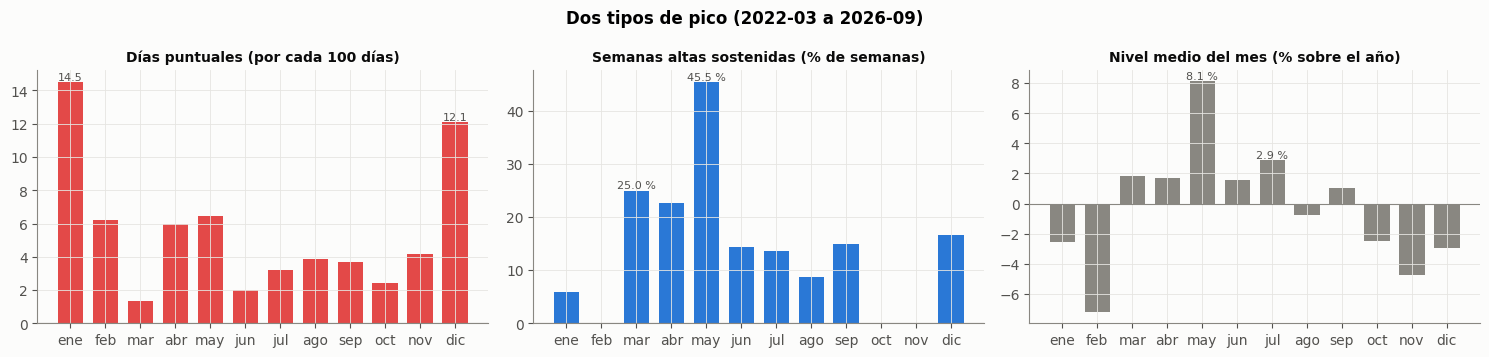

,días puntuales /100 días,semanas altas %,nivel del mes %
ene,14.5,6.0,-2.6
feb,6.2,0.0,-7.2
mar,1.4,25.0,1.8
abr,6.0,23.0,1.7
may,6.5,45.0,8.1
jun,2.0,14.0,1.6
jul,3.2,14.0,2.9
ago,3.9,9.0,-0.8
sep,3.7,15.0,1.0
oct,2.4,0.0,-2.5


In [3]:
meses = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
p15 = local > 1.5 * sd
dias_mes = local.notna().groupby(local.index.month).sum()
puntuales = 100 * p15.groupby(p15.index.month).sum() / dias_mes
w = V.total.resample("W-SAT").mean()[V.total.resample("W-SAT").count() == 7]
alta = w > w.std()
sostenidas = 100 * alta.groupby(alta.index.month).mean()
nivel = pct(V.total.groupby(V.index.month).mean())
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, s, t, col, u in [(axes[0], puntuales, "Días puntuales (por cada 100 días)", ROJO, ""),
                         (axes[1], sostenidas, "Semanas altas sostenidas (% de semanas)", AZUL, " %"),
                         (axes[2], nivel, "Nivel medio del mes (% sobre el año)", MUDO, " %")]:
    s = s.reindex(range(1, 13)).fillna(0)
    ax.bar(range(12), s.values, color=col, width=.72)
    ax.set_xticks(range(12), meses); ax.set_title(t, fontsize=10); ax.axhline(0, color=MUDO, lw=.8)
    for i in s.values.argsort()[-2:]:
        ax.text(i, s.values[i], f"{s.values[i]:.1f}{u}", ha="center", va="bottom", fontsize=8, color=TINTA2)
fig.suptitle("Dos tipos de pico (2022-03 a 2026-09)", fontweight="bold"); plt.tight_layout(); plt.show()
tabla1 = pd.DataFrame({"días puntuales /100 días": puntuales.round(1), "semanas altas %": sostenidas.round(0),
                       "nivel del mes %": nivel.round(1)}).reindex(range(1, 13)); tabla1.index = meses
tabla1


## Lectura

**Hay dos tipos de pico y no se parecen.**

| | Días puntuales (por cada 100 días) | Semanas altas (%) | Nivel del mes |
|---|---|---|---|
| **Enero** | **14,5** | 6 | −2,6 % |
| **Diciembre** | **12,1** | 17 | −2,9 % |
| Marzo-abril | 1,4-6,0 | 23-25 | +1,7 a +1,8 % |
| **Mayo** | 6,5 | **45** | **+8,1 %** |
| Octubre-noviembre | 2,4-4,2 | **0** | −2,5 a −4,7 % |

Diciembre y enero concentran los días sueltos muy altos dentro de meses que en conjunto son bajos: son noches y días concretos, no temporadas. Marzo a mayo, en cambio, reúne semanas enteras altas, y octubre y noviembre no tienen ni una. Un pico de diciembre y uno de mayo piden por tanto variables distintas para anticiparlos: el primero, el calendario festivo, que se conoce con meses de antelación; el segundo, lo que viene subiendo desde semanas antes.

**Límite de esta figura.** Usa el control completo, que incluye las «vacaciones escolares» del calendario. Por eso descuenta el efecto de las vacaciones de mitad de año y junio-julio salen bajos aquí. La sección 5 lo mide sin ese descuento y la conclusión sobre la mitad de año cambia.

---
# 2. Diciembre: las noches festivas

Las noches analizadas son el **7 de diciembre (velitas), el 24, el 25 y el 31 de diciembre y el 1 de enero**, y el día siguiente a cada una. El comparador son **los demás festivos y domingos del año**, que tampoco son laborales. El control (A) lleva día de la semana, festivo y año, **sin** temporada navideña, que se comería el efecto que se quiere medir. La huella esperada es madrugada, 15-44 años y particulares; el contraste externo son las **lesiones personales que registra la Policía** ese mismo día en toda la ciudad.

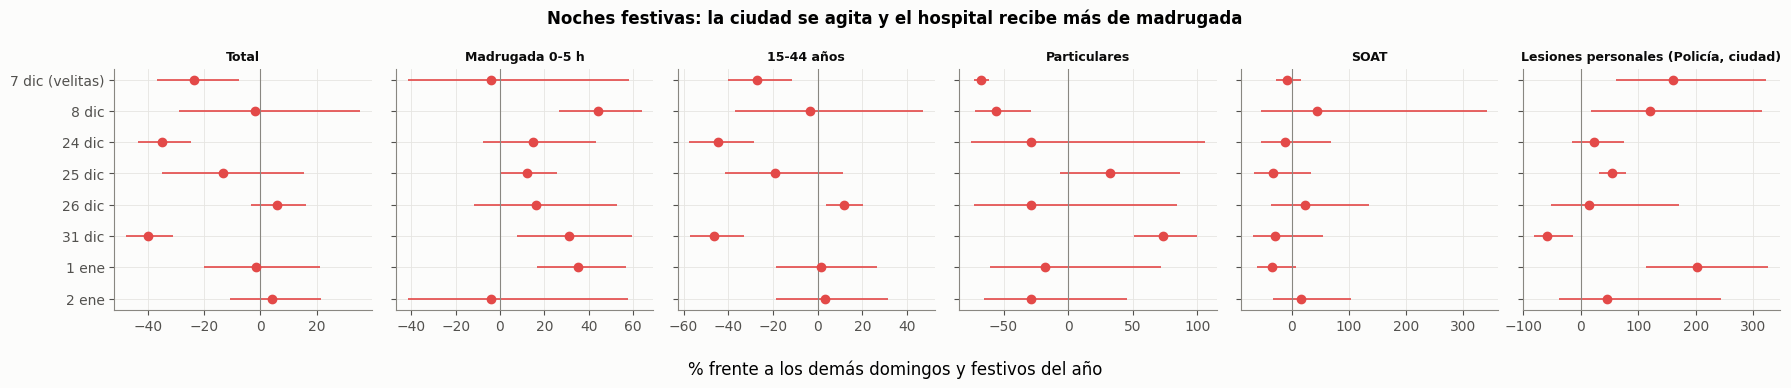

serie,Total,Madrugada 0-5 h,15-44 años,Particulares,SOAT,"Lesiones personales (Policía, ciudad)"
noche,,,,,,
7 dic (velitas),-24.0,-4.0,-27.0,-68.0,-8.0,161.0
8 dic,-2.0,44.0,-4.0,-56.0,44.0,120.0
24 dic,-35.0,15.0,-45.0,-29.0,-13.0,22.0
25 dic,-13.0,12.0,-19.0,32.0,-32.0,54.0
26 dic,6.0,16.0,12.0,-29.0,23.0,14.0
31 dic,-40.0,31.0,-47.0,74.0,-30.0,-59.0
1 ene,-2.0,35.0,2.0,-18.0,-35.0,201.0
2 ene,4.0,-4.0,3.0,-29.0,17.0,46.0


In [4]:
fechas_dic = []
for a in range(2020, 2027):
    for m, d in [(12, 7), (12, 8), (12, 24), (12, 25), (12, 26), (12, 31), (1, 1), (1, 2)]:
        f = pd.Timestamp(a, m, d)
        if f in RA.index and not (pd.Timestamp(COVID[0]) <= f <= pd.Timestamp(COVID[1])): fechas_dic.append(f)
fechas_dic = pd.DatetimeIndex(sorted(set(fechas_dic)))
comparador = RA.index[((dow == 6) | (fest == 1)) & ~RA.index.isin(fechas_dic) & ~RA.index.month.isin([12, 1]) & fuera]
nombres = {(12, 7): "7 dic (velitas)", (12, 8): "8 dic", (12, 24): "24 dic", (12, 25): "25 dic", (12, 26): "26 dic",
           (12, 31): "31 dic", (1, 1): "1 ene", (1, 2): "2 ene"}
cols = {"total": "Total", "madrugada": "Madrugada 0-5 h", "15-44": "15-44 años", "particular": "Particulares",
        "soat_aseguradora": "SOAT", "lesiones_ciudad": "Lesiones personales (Policía, ciudad)"}
filas = []
for c, nom in cols.items():
    base = RA[c].loc[comparador].dropna()
    for (m, d), nd in nombres.items():
        x = RA[c].loc[[f for f in fechas_dic if f.month == m and f.day == d]].dropna()
        if len(x) < 2: continue
        dif = x.mean() - base.mean(); e = 1.96 * np.sqrt(x.var() / len(x) + base.var() / len(base))
        filas.append({"serie": nom, "noche": nd, "efecto %": pct(dif), "bajo": pct(dif - e), "alto": pct(dif + e), "años": len(x)})
T2 = pd.DataFrame(filas)
fig, axes = plt.subplots(1, len(cols), figsize=(18, 3.8), sharey=True)
orden = list(nombres.values())
for ax, (s, g) in zip(axes, T2.groupby("serie", sort=False)):
    g = g.set_index("noche").reindex(orden).dropna()
    y = [orden.index(i) for i in g.index]
    ax.errorbar(g["efecto %"], y, xerr=[g["efecto %"] - g.bajo, g.alto - g["efecto %"]], fmt="o", color=ROJO, ms=6, lw=1.2)
    ax.axvline(0, color=MUDO, lw=.8); ax.set_title(s, fontsize=9)
axes[0].set_yticks(range(len(orden)), orden); axes[0].invert_yaxis()
fig.suptitle("Noches festivas: la ciudad se agita y el hospital recibe más de madrugada", fontweight="bold")
fig.supxlabel("% frente a los demás domingos y festivos del año"); plt.tight_layout(); plt.show()
T2.pivot_table(index="noche", columns="serie", values="efecto %", sort=False).reindex(orden).round(0)


In [5]:
T2[T2.serie.isin(["Madrugada 0-5 h", "Lesiones personales (Policía, ciudad)"])].set_index(["serie", "noche"]).round(0)

efecto %   bajo   alto  \
serie                                 noche                                     
Madrugada 0-5 h                       7 dic (velitas)      -4.0  -42.0   58.0   
                                      8 dic                44.0   27.0   64.0   
                                      24 dic               15.0   -8.0   43.0   
                                      25 dic               12.0    0.0   26.0   
                                      26 dic               16.0  -12.0   53.0   
                                      31 dic               31.0    8.0   60.0   
                                      1 ene                35.0   17.0   57.0   
                                      2 ene                -4.0  -42.0   58.0   
Lesiones personales (Policía, ciudad) 7 dic (velitas)     161.0   61.0  322.0   
                                      8 dic               120.0   17.0  315.0   
                                      24 dic               22.0  -15.0   76.0   
                                      25 dic               54.0   32.0   78.0   
                                      26 dic               14.0  -52.0  170.0   
                                      31 dic              -59.0  -81.0  -13.0   
                                      1 ene               201.0  113.0  326.0   
                                      2 ene                46.0  -38.0  244.0   

                                                       años  
serie                                 noche                  
Madrugada 0-5 h                       7 dic (velitas)     4  
                                      8 dic               4  
                                      24 dic              4  
                                      25 dic              4  
                                      26 dic              4  
                                      31 dic              4  
                                      1 ene               5  
                                      2 ene               5  
Lesiones personales (Policía, ciudad) 7 dic (velitas)     4  
                                      8 dic               4  
                                      24 dic              4  
                                      25 dic              4  
                                      26 dic              4  
                                      31 dic              4  
                                      1 ene               5  
                                      2 ene               5

In [6]:
# Polvora: SIVIGILA 452 en Manizales, semanas de diciembre y enero contra el resto
man = vig[vig.ambito.eq("manizales") & vig.evento.eq(452)]
v452 = man[man.variable.eq("casos_ocurrencia")].groupby("fecha_inicio_semana")["valor"].sum()
v452 = v452.loc["2015":]
temporada = v452.index.month.isin([12, 1])
print(f"Lesiones por pólvora en Manizales (SIVIGILA 452, 2015-2025): {int(v452.sum())} casos")
print(f"  en semanas de dic-ene: {int(v452[temporada].sum())} ({100*v452[temporada].sum()/v452.sum():.0f} %)")
print(f"  casos por semana en temporada: {v452[temporada].mean():.2f}; resto del año: {v452[~temporada].mean():.2f}")


Lesiones por pólvora en Manizales (SIVIGILA 452, 2015-2025): 163 casos
  en semanas de dic-ene: 131 (80 %)
  casos por semana en temporada: 1.34; resto del año: 0.07


## Lectura

**Las noches festivas no suben el día: lo mueven a la madrugada y a otra gente.** Todo se compara con los demás domingos y festivos del año.

| Noche | Total | Madrugada | Particulares | Lesiones (Policía, ciudad) |
|---|---|---|---|---|
| 7 dic (velitas) | **−24 %** | −4 % | −68 % | **+161 %** |
| 8 dic | −2 % | **+44 %** | −56 % | **+120 %** |
| 24 dic | **−35 %** | +15 % | −29 % | +22 % |
| 25 dic | −13 % | +12 % | +32 % | **+54 %** |
| 31 dic | **−40 %** | **+31 %** | **+74 %** | −59 % |
| 1 ene | −2 % | **+35 %** | −18 % | **+201 %** |

1. **En la ciudad, las noches de fiesta son violentas.** Las lesiones personales se multiplican por 2,6 en velitas (+161 %, intervalo [+61; +322]), por 2,2 el 8 de diciembre (+120 % [+17; +315]) y por 3 el 1 de enero (+201 % [+113; +326]); el 25 sube +54 % [+32; +78]. El 31 aparece en −59 % [−81; −13], y lo más probable es que las riñas de esa noche caigan después de medianoche, ya el 1 de enero. Es el patrón esperado de alcohol, riñas y fiesta.
2. **En el SES el día completo baja** en velitas, el 24 y el 31, entre un 24 y un 40 % frente a otro festivo: la gente está en casa o de fiesta. **Pero la madrugada sube**: +44 % [+27; +64] la del 8 de diciembre, +31 % [+8; +60] la del 31 y +35 % [+17; +57] la del 1 de enero (el 25 queda en +12 % [0; +26], en el borde). Lo que llega esas noches llega de madrugada.
3. **El 31 llegan +74 % de particulares**, personas sin asegurador a mano, lo que encaja con visitantes y con quien no pasa por su EPS en festivo.
4. **La pólvora es real, pero pequeña en el conteo.** El 80 % de los quemados de Manizales en SIVIGILA (131 de 163, 2015-2025) cae en diciembre-enero: 1,3 casos por semana en temporada contra 0,07 el resto del año. Frente a unos 177 triages diarios, no explica el pico por sí sola.

**Límites.**
- Cada noche tiene 4-5 años de datos, de modo que los intervalos son anchos; solo son firmes las marcas cuya barra no cruza el cero.
- La serie de la Policía es de toda la ciudad y no dice cuántos de esos lesionados llegaron al SES.
- Un indicador único de «festivo» promedia la noche, que baja de día y sube de madrugada, con el día siguiente, que sube (sección 3): ambas cosas se anulan entre sí.

---
# 3. La temporada de fin de año, día por día

Residuo del total (control A) del 1 de diciembre al 31 de enero, un año por línea, con la media en azul. Las marcas señalan el 7 de diciembre, el 24, el 25, el 31, el 1 de enero, Reyes y el inicio de la Feria de cada año.

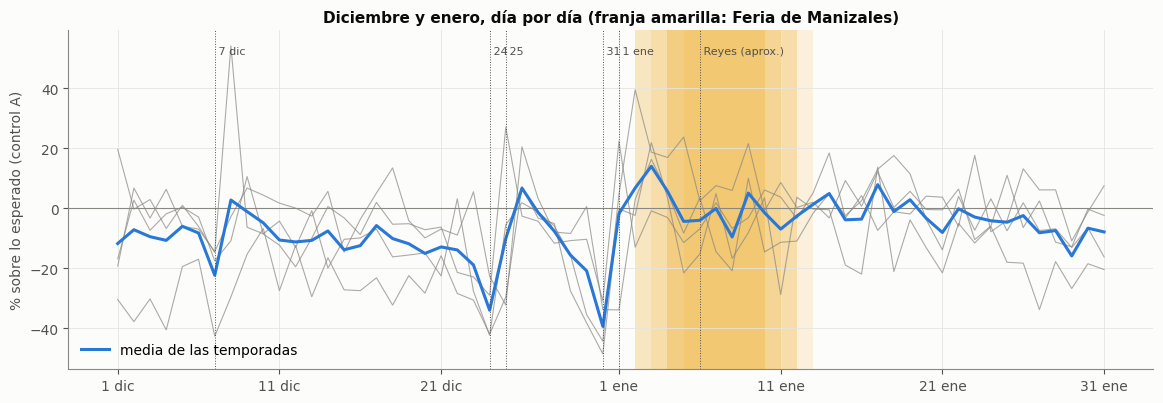

,media %,temporadas
03-Jan,14.0,4
17-Jan,7.8,4
02-Jan,6.7,4
26-Dec,6.7,4
04-Jan,5.6,4
09-Jan,5.0,4
14-Jan,4.9,4
19-Jan,2.8,4
08-Dec,2.7,4
13-Jan,1.2,4


In [7]:
curvas = {}
for a in range(2023, 2027):          # desde dic-2022: la temporada 2021-22 cae en la ventana COVID, fuera del ajuste
    ini = pd.Timestamp(a - 1, 12, 1); fin = pd.Timestamp(a, 1, 31)
    s = RA.total.loc[ini:fin]
    if s.notna().sum() < 40: continue
    s.index = (s.index - ini).days
    curvas[f"{a-1}-{a}"] = pct(s)
Mx = pd.DataFrame(curvas)
fig, ax = plt.subplots(figsize=(14, 4.4))
ax.axhline(0, color=MUDO, lw=.8)
for c in Mx.columns: ax.plot(Mx.index, Mx[c], color=MUDO, lw=.8, alpha=.7)
ax.plot(Mx.index, Mx.mean(axis=1), color=AZUL, lw=2.2, label="media de las temporadas")
marcas = {6: "7 dic", 23: "24", 24: "25", 30: "31", 31: "1 ene", 36: "Reyes (aprox.)"}
for k, t in marcas.items():
    ax.axvline(k, color=TINTA2, lw=.7, ls=":"); ax.text(k, Mx.max().max() * .95, " " + t, fontsize=8, color=TINTA2)
ferias = eventos[eventos.nombre_evento.eq("Feria de Manizales") & eventos.estado.eq("realizado")]
for _, f in ferias.iterrows():
    k = (pd.Timestamp(f.fecha_inicio) - pd.Timestamp(pd.Timestamp(f.fecha_inicio).year - 1, 12, 1)).days
    if 0 <= k <= 61: ax.axvspan(k, k + 8, color=AMARILLO, alpha=.12, lw=0)
ax.set_xticks([0, 10, 20, 31, 41, 51, 61], ["1 dic", "11 dic", "21 dic", "1 ene", "11 ene", "21 ene", "31 ene"])
ax.set_ylabel("% sobre lo esperado (control A)"); ax.legend(loc="lower left")
ax.set_title("Diciembre y enero, día por día (franja amarilla: Feria de Manizales)"); plt.show()
top = pd.DataFrame({"media %": Mx.mean(axis=1).round(1), "temporadas": Mx.notna().sum(axis=1)})
top.index = [(pd.Timestamp(2021, 12, 1) + pd.Timedelta(days=int(i))).strftime("%d-%b") for i in top.index]
top.sort_values("media %", ascending=False).head(10)


In [8]:
# la temporada 2021-22 cae dentro de la ventana COVID: el ajuste del control A no tiene ni un dia de 2021
print("dias de 2021 usados para ajustar el control A:", int(ZA.loc[fuera, "a_2021"].sum()))
mx = pd.DataFrame({k: pct(RA.total.loc[f"{k-1}-12-01":f"{k}-01-31"]).values[:62] for k in range(2022, 2027)})
con, sin = mx.mean(axis=1), mx.drop(columns=2022).mean(axis=1)
pd.DataFrame({"con 2021-22 (5 temporadas) %": con.iloc[7:10].round(1).values,
              "sin 2021-22 (4 temporadas) %": sin.iloc[7:10].round(1).values}, index=["8 dic", "9 dic", "10 dic"])

dias de 2021 usados para ajustar el control A: 0


,con 2021-22 (5 temporadas) %,sin 2021-22 (4 temporadas) %
8 dic,11.0,2.7
9 dic,17.2,-1.1
10 dic,12.9,-4.9


## Lectura

**El pico de fin de año llega el día después, no la noche de fiesta.** Los días más altos de diciembre y enero, en media de las 4 temporadas limpias (dic-2022 a ene-2026):

| Día | Media sobre lo esperado |
|---|---|
| **3 de enero** | **+14,0 %** |
| 17 de enero | +7,8 % |
| 2 de enero | +6,7 % |
| 26 de diciembre | +6,7 % |
| 4 de enero | +5,6 % |
| 9 de enero | +5,0 % |

- La figura muestra un **pozo y un rebote**. Las noches del 24 y del 31 hunden el conteo (−30 a −40 %) y los días siguientes vuelven por encima de lo normal, sobre todo del 2 al 4 de enero. La fiesta pasa y la consecuencia llega después, cuando la gente decide consultar o vuelve a haber servicio normal.
- **Del 2 al 4 de enero se juntan tres cosas** que con 4 temporadas no se pueden separar: el día después de Año Nuevo, el regreso de las vacaciones y el arranque de la Feria (franja amarilla). El cuaderno 07 mostró que la Feria sí tiene huella propia (SOAT +37 % frente a +12 % de otros regresos).
- El Carnaval de Riosucio (enero de 2023 y 2025) coincide con esas mismas fechas.

**El diciembre falso de la temporada 2021-22.** Una primera versión de la curva incluía la temporada 2021-22. Todo 2021 cae dentro de la ventana COVID que el ajuste excluye, de modo que el control no tiene **ningún día de 2021** (0 días en la celda anterior) y el nivel de ese año queda sin anclar. Con esa temporada incluida, el 8, 9 y 10 de diciembre salían como los picos más altos de la curva (+11,0, +17,2 y +12,9 %); sin ella quedan en +2,7, −1,1 y −4,9 %. **La temporada COVID fabricaba el pico de velitas**: el pico decembrino real está en el día después, no en el 8 de diciembre. Por la misma razón, el 8 de diciembre de 2024 (+54 %, sección 6) es un caso aislado de un solo año y no una regularidad.

---
# 4. Las fiestas de los pueblos

Se toman los días de fiesta **realizada** en municipios de Caldas y los 3 días siguientes. Se mira el total y **quién paga**: particulares, ente territorial e IPS remitente, que es la huella de quien llega sin EPS a mano o remitido. Se separa por distancia a Manizales. Se usa el control (B) completo; las fiestas coinciden a menudo con puentes festivos y ese control ya los descuenta.

In [9]:
RBg = pd.DataFrame({c: residuo(S[c], ZB) for c in ["total", "particular", "ente_territorial", "ips_remitente", "15-44", "madrugada"]}, index=dias)
ok = fiestas.estado.isin(["realizado", "virtual"]) & fiestas.fecha_inicio.notna()
F = fiestas[ok].copy(); F["ini"] = pd.to_datetime(F.fecha_inicio); F["fin"] = pd.to_datetime(F.fecha_fin).fillna(F["ini"])
F = F[(F.ini >= pd.Timestamp(INI)) & (F.ini <= pd.Timestamp(FIN))]
filas = []
for nom, sel in [("cerca (< 60 km)", F.distancia_km_manizales < 60), ("lejos (≥ 60 km)", F.distancia_km_manizales >= 60), ("todas", F.index == F.index)]:
    marca = pd.Series(False, index=dias)
    for _, f in F[sel].iterrows(): marca.loc[f.ini: f.fin + pd.Timedelta(days=3)] = True
    marca = marca.loc[INI:FIN]
    for c in RBg.columns:
        y = RBg[c].loc[INI:FIN]; a, b = y[marca].dropna(), y[~marca].dropna()
        d = a.mean() - b.mean(); e = 1.96 * np.sqrt(a.var() / len(a) + b.var() / len(b))
        filas.append({"fiestas": nom, "serie": c, "efecto %": round(pct(d), 1), "IC95": f"[{pct(d-e):+.1f}; {pct(d+e):+.1f}]",
                      "días de fiesta": int(marca.sum()), "fiestas n": int(sel.sum())})
T4 = pd.DataFrame(filas)
print(f"{len(F)} fiestas realizadas con fecha en 2022-03 a 2026-09")
T4.pivot_table(index="serie", columns="fiestas", values="efecto %", aggfunc="first")


107 fiestas realizadas con fecha en 2022-03 a 2026-09


fiestas,cerca (< 60 km),lejos (≥ 60 km),todas
serie,,,
15-44,0.1,2.1,1.6
ente_territorial,4.8,3.8,4.2
ips_remitente,-10.3,-4.9,-6.0
madrugada,-0.3,2.1,1.7
particular,-5.9,-7.5,-7.5
total,0.2,1.9,1.7


In [10]:
T4

,fiestas,serie,efecto %,IC95,días de fiesta,fiestas n
0,cerca (< 60 km),total,0.2,[-1.3; +1.8],195,30
1,cerca (< 60 km),particular,-5.9,[-15.8; +5.2],195,30
2,cerca (< 60 km),ente_territorial,4.8,[-4.9; +15.6],195,30
3,cerca (< 60 km),ips_remitente,-10.3,[-18.2; -1.6],195,30
4,cerca (< 60 km),15-44,0.1,[-1.7; +2.0],195,30
5,cerca (< 60 km),madrugada,-0.3,[-5.2; +4.8],195,30
6,lejos (≥ 60 km),total,1.9,[+0.5; +3.4],296,77
7,lejos (≥ 60 km),particular,-7.5,[-15.8; +1.7],296,77
8,lejos (≥ 60 km),ente_territorial,3.8,[-4.9; +13.4],296,77
9,lejos (≥ 60 km),ips_remitente,-4.9,[-12.2; +2.9],296,77


## Lectura

**Las fiestas de los pueblos dejan una huella pequeña, y solo las lejanas.** Efecto durante la fiesta y los 3 días siguientes, con el control completo:

| | Fiestas cercanas (< 60 km, 30) | **Fiestas lejanas (≥ 60 km, 77)** | Todas (107) |
|---|---|---|---|
| Total | +0,2 % [−1,3; +1,8] | **+1,9 % [+0,5; +3,4]** | **+1,7 % [+0,4; +3,0]** |
| 15-44 años | +0,1 % | **+2,1 % [+0,4; +3,8]** | +1,6 % |
| Ente territorial | +4,8 % | +3,8 % | +4,2 % (no significativo) |
| IPS remitente | **−10,3 % [−18,2; −1,6]** | −4,9 % | −6,0 % |
| Particulares | −5,9 % | −7,5 % | −7,5 % (no significativo) |

- **Durante las fiestas de los municipios lejanos el triage del SES sube un 2 %**, sobre todo en adultos de 15 a 44 años. Es lo que predice la hipótesis de remisión: un pueblo lejano, con un hospital pequeño, remite lo que no puede atender; un pueblo cercano no.
- **Pero la huella del asegurador no acompaña.** No suben los particulares ni las IPS remitentes, y el ente territorial sube sin ser significativo. Quien llega viene con su EPS habitual, o la remisión no queda registrada como «IPS remitente».
- **El tamaño es pequeño**: 2 %, frente a un ruido diario del 12 %. Suma a un modelo, pero no explica picos por sí sola; en la sección 6 las fiestas de pueblos lejanos solo coinciden con 4 de los 30 picos notables.

**Límites.**
- Son 18 comparaciones, así que alguna saldría «significativa» por azar. El patrón «lejos > cerca» es lo que da algo de confianza.
- Las fiestas caen muchas veces en puentes festivos. El control los descuenta, pero puede quedar algo de efecto puente.
- La prueba directa de la hipótesis de remisión sería la serie de remisiones del CRUE, que no está disponible; sin ella, esta sección solo muestra que la huella es compatible con remisión, no que lo sea.

---
# 5. La mitad de año

Se comparan las **semanas de vacaciones escolares oficiales** (resoluciones de la Secretaría de Educación de Manizales) con las semanas de clase de marzo a julio. Además, y **declarado como mirado después**, se examina el alto sostenido de marzo a mayo (sección 1). La figura muestra, año por año, el residuo semanal del total (control A: sin quitar la estacionalidad) de febrero a agosto, con las vacaciones sombreadas y la IRA de la ciudad (SIVIGILA 995 sin el SES) en índice.

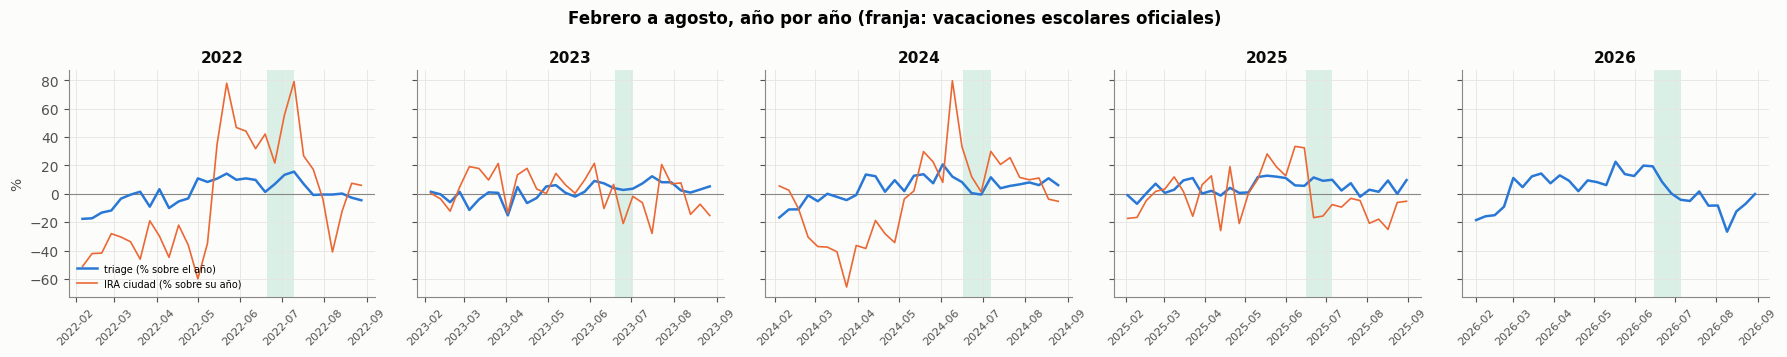

,semanas de vacaciones %,marzo-mayo %
año,,
2022,9.3,2.1
2023,3.5,-1.7
2024,4.9,5.2
2025,9.0,5.2
2026,6.0,10.5
media,6.5,4.3


In [11]:
VAC = {2022: ("2022-06-20", "2022-07-10"), 2023: ("2023-06-19", "2023-07-02"), 2024: ("2024-06-17", "2024-07-07"),
       2025: ("2025-06-16", "2025-07-06"), 2026: ("2026-06-15", "2026-07-05")}   # 2026: sin clases desde el 15-jun
wA = RA.total.resample("W-SAT").mean().rename(lambda i: i - pd.Timedelta(days=6))
wA = wA[RA.total.resample("W-SAT").count().values == 7]
inst = pd.read_csv(RAIZ / "calendarios/vigilancia_sivigila_instituciones.csv.gz", parse_dates=["fecha_inicio_semana"])
ira = inst[inst.cod_upgd.ne(170010010301)].groupby("fecha_inicio_semana")["consultas_ira"].sum()
fig, axes = plt.subplots(1, 5, figsize=(18, 3.6), sharey=True)
filas = []
for ax, (a, (vi, vf)) in zip(axes, VAC.items()):
    s = pct(wA.loc[f"{a}-02-01":f"{a}-08-31"]); ax.axhline(0, color=MUDO, lw=.8)
    ax.axvspan(pd.Timestamp(vi), pd.Timestamp(vf), color=AQUA, alpha=.15, lw=0)
    ax.plot(s.index, s.values, color=AZUL, lw=1.8, label="triage (% sobre el año)")
    ii = ira.loc[f"{a}-02-01":f"{a}-08-31"]
    if len(ii) > 5:
        ax.plot(ii.index, 100 * (ii / ira.loc[f"{a}"].mean() - 1), color=NARANJA, lw=1.2, label="IRA ciudad (% sobre su año)")
    ax.set_title(str(a)); ax.tick_params(axis="x", labelrotation=45, labelsize=8)
    vac = s[(s.index >= pd.Timestamp(vi) - pd.Timedelta(days=6)) & (s.index <= pd.Timestamp(vf))]
    clase = s[(s.index.month.isin([3, 4, 5])) ]
    filas.append({"año": a, "semanas de vacaciones %": round(vac.mean(), 1), "marzo-mayo %": round(clase.mean(), 1)})
axes[0].set_ylabel("%"); axes[0].legend(fontsize=7, loc="lower left")
fig.suptitle("Febrero a agosto, año por año (franja: vacaciones escolares oficiales)", fontweight="bold")
plt.tight_layout(); plt.show()
T5 = pd.DataFrame(filas).set_index("año"); T5.loc["media"] = T5.mean().round(1)
T5


## Lectura

**La mitad del año es la parte alta del año, y las vacaciones escolares están dentro de ella.** Medido sin descontar las vacaciones (control A: día de la semana, festivo y año):

| Año | Semanas de vacaciones escolares | Marzo-mayo |
|---|---|---|
| 2022 | **+9,3 %** | +2,1 % |
| 2023 | +3,5 % | −1,7 % |
| 2024 | +4,9 % | +5,2 % |
| 2025 | **+9,0 %** | +5,2 % |
| 2026 | +6,0 % | **+10,5 %** |
| **Media** | **+6,5 %** | **+4,3 %** |

- Las semanas de vacaciones escolares de mitad de año están **por encima del nivel del año los cinco años**, de +3,5 a +9,3 %. Marzo-mayo también está alto (+4,3 % de media).
- **La sección 1 daba otra lectura** (el alto en mayo y junio-julio bajos) porque su control incluye las «vacaciones escolares» del calendario, 122 fechas fijas cada año, y las descuenta. Un control que contiene la variable que se quiere estudiar la hace desaparecer. Con el control A, que no la contiene, las vacaciones aparecen entre lo más alto del año.
- **La IRA de la ciudad** (naranja) sube con fuerza de mayo a julio en 2022 y en junio de 2024, que es la temporada respiratoria de mitad de año; en 2023 y 2025 es más plana. El triage no sigue a la IRA semana a semana (cuaderno 07), pero ambas comparten temporada.

**Límites.**
- Julio de 2026 cae por el desplome de Nueva EPS, no por las vacaciones (cuaderno 07, sección 5).
- Con cinco años no se puede separar «vacaciones» de «temporada respiratoria» y de «fiestas de los pueblos de finales de junio»: caen juntas.

---
# 6. Los picos notables, uno a uno

Hasta aquí se midieron factores por separado. Aquí se parte de los días: los **picos notables** son los días entre marzo de 2022 y septiembre de 2026 cuyo residuo (control completo, sección 1) supera en más de dos desviaciones (+21,9 % sobre el nivel local, es decir, 2 × 0,099 en logaritmo) la mediana de los 29 días centrados en él. El umbral es descriptivo, no una hipótesis. Para cada pico se compara el conteo por hora, banda de edad y asegurador con el mismo día de la semana de las cuatro semanas vecinas a cada lado (a ±7, ±14, ±21 y ±28 días, sin otros picos). El factor se asigna con reglas fijas: noche o día después de fiesta decembrina, arranque de año (26-27 de diciembre y 1-5 de enero), festivo, Feria de Manizales, Carnaval de Riosucio, Semana Santa, y alza pediátrica con IRA de la ciudad al menos 10 % sobre la media de su año. Las fiestas de pueblos lejanos solo se anotan como coincidencia, porque su efecto medio (+1,9 %) no alcanza para producir un pico de +22 %. Si ninguna regla aplica, se escribe «sin explicación con los datos disponibles».

In [12]:
# ---------- los picos notables: dias con el residuo (control completo) mas de 2 desviaciones sobre su nivel local
picos = local.index[local > 2 * sd]
ev = eventos[eventos.estado.eq("realizado") & eventos.fecha_inicio.notna()].copy()
ev["ini"] = pd.to_datetime(ev.fecha_inicio); ev["fin"] = pd.to_datetime(ev.fecha_fin).fillna(ev.ini)
Fp = fiestas[fiestas.estado.isin(["realizado", "virtual"]) & fiestas.fecha_inicio.notna()].copy()
Fp["ini"] = pd.to_datetime(Fp.fecha_inicio); Fp["fin"] = pd.to_datetime(Fp.fecha_fin).fillna(Fp.ini)
hp = hor.pivot_table(index="dia", columns="hora", values="triages", aggfunc="sum").reindex(dias).fillna(0)
irax = (ira / ira.groupby(ira.index.year).transform("mean") - 1) * 100       # IRA de la ciudad, % sobre la media de su año
VACS = [(pd.Timestamp(a), pd.Timestamp(b)) for a, b in VAC.values()]
NOCHES = {(12, 7), (12, 8), (12, 24), (12, 25), (12, 26), (12, 31), (1, 1), (1, 2)}
filas, hperfil = [], []
for d in picos:
    ref = [d + pd.Timedelta(days=k) for k in range(-28, 29, 7) if k != 0]
    ref = [r for r in ref if r in hp.index and r not in picos and S.total.notna()[r]]
    exc = hp.loc[d] - hp.loc[ref].mean()
    hperfil.append(exc.values / exc.sum())
    franja = max([("madrugada (0-5 h)", exc[0:6].sum()), ("mañana (6-11 h)", exc[6:12].sum()),
                  ("tarde (12-17 h)", exc[12:18].sum()), ("noche (18-23 h)", exc[18:24].sum())], key=lambda t: t[1])[0]
    madr = (madrugada[d] / madrugada.loc[ref].mean() - 1) * 100
    er = (edad.loc[d] / edad.loc[ref].mean() - 1) * 100
    fac = []
    if (d.month, d.day) in NOCHES: fac.append("noche o día después de fiesta decembrina")
    elif fest[d] == 1: fac.append("festivo")
    if (d.month == 1 and d.day <= 5) or (d.month == 12 and d.day in (26, 27)): fac.append("arranque de año")
    if ((ev.nombre_evento == "Feria de Manizales") & (ev.ini <= d) & (ev.fin >= d)).any(): fac.append("Feria de Manizales")
    if ((Fp.nombre.str.contains("Riosucio")) & (Fp.ini <= d) & (Fp.fin + pd.Timedelta(days=3) >= d)).any(): fac.append("Carnaval de Riosucio")
    if calc.loc[d, "es_semana_santa"] == 1: fac.append("Semana Santa")
    sem = d - pd.Timedelta(days=d.dayofweek + 1) if d.dayofweek != 6 else d
    ira_s = irax.get(sem, np.nan)
    if er["0-4"] >= 50 and ira_s >= 10: fac.append("pediátrico con IRA alta")
    lej = Fp[(Fp.ini <= d) & (Fp.fin + pd.Timedelta(days=3) >= d) & (Fp.distancia_km_manizales >= 60)]
    filas.append({"fecha": d.date(), "día": "lmxjvsd"[d.dayofweek], "sobre su nivel %": round(pct(local[d])),
                  "triages": int(S.total[d]), "mayor exceso": franja, "madrugada %": round(madr),
                  "0-4 %": round(er["0-4"]), "15-44 %": round(er["15-44"]), "65+ %": round(er["65-+"]),
                  "IRA ciudad %": round(ira_s) if pd.notna(ira_s) else None,
                  "factor": "; ".join(fac) if fac else ("solo coincide con fiestas de pueblos lejanos" if len(lej) else "sin explicación con los datos disponibles")})
T6 = pd.DataFrame(filas)
print(f"{len(T6)} picos notables (más de 2 desviaciones, {pct(2 * sd):+.1f} % sobre su nivel local), 2022-03 a 2026-09; "
      f"{int(((T6['día'] == 's') | (T6['día'] == 'd')).sum())} en fin de semana")
print(T6["factor"].apply(lambda s: "sin explicación" if s.startswith("sin ") else ("solo fiestas" if s.startswith("solo") else "con factor")).value_counts().to_string())
print(T6["mayor exceso"].value_counts().to_string())
print(f"madrugada con alza de 30 % o más: {int((T6['madrugada %'] >= 30).sum())} de {len(T6)} picos; mediana {T6['madrugada %'].median():.0f} %")
T6.set_index("fecha")


30 picos notables (más de 2 desviaciones, +21.9 % sobre su nivel local), 2022-03 a 2026-09; 18 en fin de semana
factor
con factor         18
sin explicación     8
solo fiestas        4
mayor exceso
mañana (6-11 h)    13
tarde (12-17 h)    12
noche (18-23 h)     5


madrugada con alza de 30 % o más: 17 de 30 picos; mediana 32 %


,día,sobre su nivel %,triages,mayor exceso,madrugada %,0-4 %,15-44 %,65+ %,IRA ciudad %,factor
fecha,,,,,,,,,,
2022-05-01,d,42,170,mañana (6-11 h),31,25,38,-5,-60.0,festivo
2022-05-23,l,23,320,mañana (6-11 h),4,117,35,5,78.0,pediátrico con IRA alta
2022-07-07,j,28,274,tarde (12-17 h),74,-10,9,76,55.0,solo coincide con fiestas de pueblos lejanos
2022-12-25,d,25,133,tarde (12-17 h),-14,100,-7,14,8.0,noche o día después de fiesta decembrina
2023-04-13,j,24,245,tarde (12-17 h),55,92,33,10,13.0,pediátrico con IRA alta
2023-11-16,j,22,233,mañana (6-11 h),32,-33,31,33,-18.0,solo coincide con fiestas de pueblos lejanos
2024-01-03,x,27,282,tarde (12-17 h),37,124,29,37,1.0,arranque de año
2024-01-18,j,23,276,tarde (12-17 h),-5,68,42,15,85.0,pediátrico con IRA alta
2024-02-17,s,26,210,mañana (6-11 h),48,-74,14,15,2.0,sin explicación con los datos disponibles


## Lectura de la tabla

**De 30 picos, 18 tienen un factor identificado, 4 solo coinciden con fiestas de pueblos lejanos y 8 no tienen explicación con los datos disponibles.**

- **Los cinco más altos son de fin de año o de fiesta.** El 8 de diciembre de 2024 (+54 %, domingo festivo, el día después de velitas: madrugada +47 %, 15-44 años +28 %); el 3 de enero de 2026 (+53 %, sábado, con la Feria; el mayor exceso cae entre las 18 y las 23 h y la madrugada sube +73 %); el 5 de enero de 2025 (+45 %, domingo, con la Feria y el Carnaval de Riosucio); el 1 de mayo de 2022 (+42 %, domingo de Día del Trabajo, madrugada +31 %); y el 2 de enero de 2025 (+39 %, regreso de vacaciones, madrugada +32 %).
- **Once picos caen en la temporada decembrina** (noche o día después de fiesta, y arranque de año), entre ellos la racha del 2 al 5 de enero de 2025 y el par del 3 y 4 de enero de 2026. Con el 10 de diciembre de 2025 (madrugada +71 %, 15-44 años +48 %), que coincide con fiestas de pueblos pero con ningún otro factor específico, son 12 de los 30 entre el 7 de diciembre y el 5 de enero.
- **Cuatro picos son pediátricos con IRA alta** (22-may-2022, 13-abr-2023, 18-ene-2024 y 31-may-2025): el grupo de 0-4 años sube entre +52 y +117 % y la IRA de la ciudad está entre +13 y +85 % sobre la media de su año. Son los únicos donde la banda de edad rompe el patrón general. Los conteos de 0-4 años son de unas decenas por día, de modo que esos porcentajes son ruidosos; la IRA ayuda a creerlos, no los prueba.
- **Dos picos son un festivo que el control ya descuenta en promedio** (1-may-2022 y 20-jul-2025) y uno es Semana Santa (5-abr-2026); en los tres, el pico es lo que sobra encima del festivo medio.
- **Ocho picos no tienen explicación con los datos disponibles**: 17-feb-2024, 11-abr-2024, 3-ago-2024, 1-dic-2024, 17-ene-2026, 7-feb-2026, 15-feb-2026 y 17-may-2026. El 11 de abril de 2024 tiene 0-4 años +100 % pero la IRA está −39 %, así que el factor pediátrico no cierra. En 2026 la serie de IRA no llega (termina en la semana del 28 de diciembre de 2025), por lo que el 17 de mayo de 2026 (0-4 años +42 %) no puede contrastarse.
- **Dieciocho de los 30 caen en fin de semana** (10 domingos y 8 sábados). Como el control ya trae el día de la semana, son fines de semana por encima de lo que un fin de semana ya suele subir o bajar.

**La hora.** Ningún pico tiene su mayor exceso en la madrugada (13 en la mañana, 12 en la tarde y 5 en la noche). Sin embargo la madrugada sube 30 % o más en 17 de los 30 (mediana +32 %), y aporta el 11,3 % del exceso del día frente al 6,5 % del volumen de un día normal: la madrugada pesa menos en cifras absolutas, pero se sobrerrepresenta.

Exceso medio de los picos sobre el mismo día de semanas vecinas (%):
               media  mediana  % de picos con alza
0-4 años        24.2     20.6                 63.0
5-14 años       26.6     23.1                 67.0
15-44 años      26.4     29.5                 97.0
45-64 años      18.6     16.2                 93.0
65 años o más   19.5     17.1                 83.0
total           22.8     24.2                 97.0



Cuota de 15-44 años en el total: 53.9 % en picos, 53.6 % en los demás días fuera de COVID

Exceso medio por asegurador (%):
nueva_eps    24.2
otra_eps     15.1
sura_eps     20.2

Peso de la madrugada (0-5 h) sobre el exceso del día: 11.3 % (madrugada sobre el exceso); en un día normal: 6.5 % del volumen
Picos con alza por banda: {'0-4 años': 19, '5-14 años': 20, '15-44 años': 29, '45-64 años': 28, '65 años o más': 25, 'total': 29}


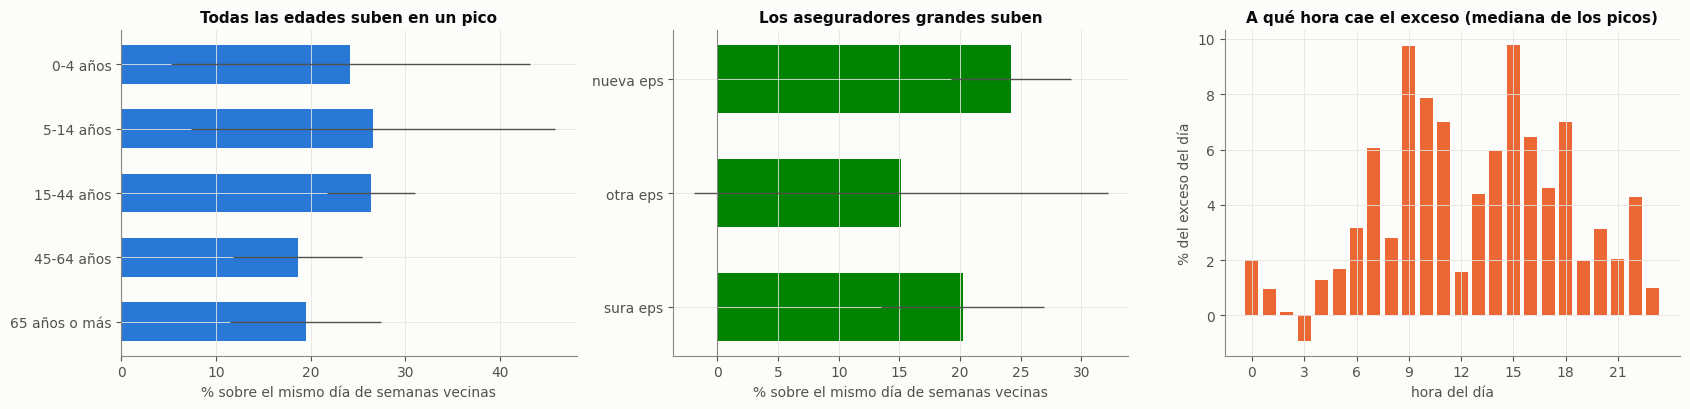

In [13]:
# ---------- composicion de los picos: exceso por banda de edad, por asegurador y por hora
bandas = {"0-4": "0-4 años", "5-14": "5-14 años", "15-44": "15-44 años", "45-64": "45-64 años", "65-+": "65 años o más"}
def exceso(serie):
    out = []
    for d in picos:
        ref = [d + pd.Timedelta(days=k) for k in range(-28, 29, 7) if k != 0]
        ref = [r for r in ref if r in serie.index and r not in picos and S.total.notna()[r]]
        out.append((serie.loc[d] / serie.loc[ref].mean() - 1) * 100)
    return pd.Series(out, index=picos)
EB = pd.DataFrame({n: exceso(edad[c]) for c, n in bandas.items()})
EB["total"] = exceso(S.total)
grupos = [c for c in grp.columns if grp[c].sum() > 0.05 * grp.values.sum()]
EG = pd.DataFrame({c: exceso(grp[c]) for c in grupos})
cuota = lambda col, sel: (edad[col][sel].sum() / edad.drop(columns="sin edad")[sel].sum().sum()) * 100
normal = ~edad.index.isin(picos) & S.total.notna().values & fuera
print("Exceso medio de los picos sobre el mismo día de semanas vecinas (%):")
print(pd.concat([EB.mean().round(1).rename("media"), EB.median().round(1).rename("mediana"),
                 (EB > 0).mean().mul(100).round(0).rename("% de picos con alza")], axis=1).to_string())
print(f"\nCuota de 15-44 años en el total: {100 * edad['15-44'][picos].sum() / edad.drop(columns='sin edad').loc[picos].sum().sum():.1f} % en picos, "
      f"{100 * edad['15-44'][normal].sum() / edad.drop(columns='sin edad')[normal].sum().sum():.1f} % en los demás días fuera de COVID")
print("\nExceso medio por asegurador (%):"); print(EG.mean().round(1).to_string())
Hh = np.array(hperfil) * 100
print(f"\nPeso de la madrugada (0-5 h) sobre el exceso del día: {Hh[:, :6].sum(axis=1).mean():.1f} % (madrugada sobre el exceso); en un día normal: "
      f"{100 * hp[S.total.notna() & fuera].iloc[:, :6].sum().sum() / hp[S.total.notna() & fuera].sum().sum():.1f} % del volumen")
print("Picos con alza por banda:", (EB > 0).sum().to_dict())
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
ax = axes[0]
m = EB.drop(columns="total"); mu = m.mean(); se = m.std() / np.sqrt(len(m))
ax.barh(range(len(mu)), mu.values, xerr=1.96 * se.values, color=AZUL, height=.6, error_kw=dict(ecolor=TINTA2, lw=1))
ax.set_yticks(range(len(mu)), mu.index); ax.invert_yaxis(); ax.axvline(0, color=MUDO, lw=.8)
ax.set_xlabel("% sobre el mismo día de semanas vecinas"); ax.set_title("Todas las edades suben en un pico")
ax = axes[1]
mg = EG.mean(); sg = EG.std() / np.sqrt(len(EG))
ax.barh(range(len(mg)), mg.values, xerr=1.96 * sg.values, color=VERDE, height=.6, error_kw=dict(ecolor=TINTA2, lw=1))
ax.set_yticks(range(len(mg)), [c.replace("_", " ") for c in mg.index]); ax.invert_yaxis(); ax.axvline(0, color=MUDO, lw=.8)
ax.set_xlabel("% sobre el mismo día de semanas vecinas"); ax.set_title("Los aseguradores grandes suben")
ax = axes[2]
H = np.array(hperfil) * 100
ax.bar(range(24), np.nanmedian(H, axis=0), color=NARANJA, width=.75)
ax.set_xticks(range(0, 24, 3)); ax.set_xlabel("hora del día"); ax.set_ylabel("% del exceso del día")
ax.set_title("A qué hora cae el exceso (mediana de los picos)")
plt.tight_layout(); plt.show()


## Lectura: un pico es de toda la demanda

**Un pico no es de un grupo: suben todas las edades y todos los aseguradores grandes a la vez.** Exceso medio de los 30 picos sobre el mismo día de semanas vecinas:

| Banda de edad | Exceso medio | Picos con alza |
|---|---|---|
| 0-4 años | +24,2 % | 19 de 30 |
| 5-14 años | +26,6 % | 20 |
| **15-44 años** | **+26,4 %** | **29** |
| 45-64 años | +18,6 % | 28 |
| 65 años o más | +19,5 % | 25 |
| Total | +22,8 % | 29 |

- La cuota de 15-44 años es la misma en los picos (53,9 %) que en los demás días fuera de COVID (53,6 %): la **composición del día no cambia**. Las bandas pediátricas suben en promedio igual que las demás, pero con menos regularidad (19 y 20 de 30), porque sus conteos diarios son pequeños y ruidosos.
- Por asegurador, los tres grandes suben: Nueva EPS +24,2 %, Sura +20,2 % y las demás EPS +15,1 %. Ningún asegurador explica el pico.
- El exceso sigue la forma del día: se reparte entre las dos jorobas (9-10 h y 14-15 h), sin concentrarse en una franja.

Esto coincide con lo medido en el cuaderno 14 para los estados de pico del conteo (todas las bandas de edad suben entre +16 y +27 %, con la composición intacta) y apunta a un cambio de **acceso y red**, o a una demanda general, antes que a una epidemia o a un grupo que consulta por una razón propia. Es la misma lectura de la sección 2: la noche festiva sube la madrugada para todos, no solo para los 15-44. La excepción son los cuatro picos pediátricos con IRA alta, que sí tienen firma propia.

**Límites.**
- 30 picos son pocos para separar efectos por banda: los intervalos de la figura de edades son anchos y no permiten decir que una banda sube más que otra.
- El umbral de 2 desviaciones es descriptivo y se fijó mirando la distribución; con otro umbral cambiaría la lista, no la lectura general.
- La asignación de factor es por reglas sobre coincidencia de fecha y no demuestra causalidad: «Feria» significa que la Feria estaba en curso, no que la causó.

---
# 7. Conclusiones: los picos tienen tres relojes

| Tipo de pico | Cuándo | Qué lo rodea | Reloj | Cómo se anticipa |
|---|---|---|---|---|
| **Noche festiva y día después** | 7-8 dic, 24-26 dic, 31 dic - 4 ene | Riñas (lesiones ×2-3 en la ciudad), alcohol, pólvora, particulares; **madrugada +31 a +44 %** | horas a 3 días | **calendario festivo**, conocido con meses |
| **Arranque de año** | 2-4 ene (+6 a +14 %) | Año Nuevo, regreso de vacaciones, Feria (SOAT +37 %), Carnaval de Riosucio | 0-5 días | calendario y la huella de la Feria |
| **Temporada de mitad de año** | marzo a julio; vacaciones escolares **+6,5 %** | IRA de la ciudad, vacaciones, fiestas de los pueblos de finales de junio | semanas | nivel de las semanas previas, vigilancia, calendario escolar |
| Fiestas de los pueblos lejanos | finales de junio y octubre-noviembre | remisiones probables, sin serie del CRUE para comprobarlas | días | calendario de fiestas: **+2 %** |

Debajo de todo está **el nivel**, que lo mueve la red (Nueva EPS). No es un pico, pero determina cuánto vale cada uno.

**Conclusiones**

1. Hay dos tipos de pico: **días puntuales** (enero 14,5 y diciembre 12,1 por cada 100 días) y **semanas altas sostenidas** (mayo, 45 % de las semanas).
2. La noche festiva **baja el día y sube la madrugada**: la ciudad sube entre +161 y +201 % en lesiones personales en velitas y el 1 de enero (+120 % el 8 de diciembre), y la madrugada del hospital sube entre +31 y +44 % el 8 de diciembre, el 31 y el 1 de enero. El pico decembrino del hospital llega **el día después**, del 2 al 4 de enero (+14,0 % el 3).
3. El pico de velitas que parecía existir en la temporada 2021-22 era un artefacto de ajustar sin ningún día de 2021; sin esa temporada, el 8-10 de diciembre queda entre −4,9 y +2,7 %.
4. La mitad del año es la parte alta del año: las semanas de vacaciones oficiales están sobre el nivel en los cinco años (+6,5 % de media).
5. Las fiestas de los pueblos lejanos suman +1,9 %, una huella real pero pequeña.
6. De 30 picos notables, 18 tienen factor identificado, 4 solo coinciden con fiestas de pueblos y **8 no tienen explicación con los datos disponibles**.
7. **Un pico es de toda la demanda**: todas las bandas de edad y los tres aseguradores grandes suben a la vez, con la composición del día intacta. Solo los 4 picos pediátricos con IRA alta tienen una firma de edad propia.

**Implicaciones para el modelo.**
- El calendario festivo no puede ser solo «es festivo»: la noche de fiesta (baja de día, sube de madrugada) y el día siguiente (sube) deben distinguirse, porque un único indicador promedia las dos cosas y las borra.
- Las vacaciones escolares de mitad de año son una variable propia, con las fechas oficiales de cada año y no las 122 fechas fijas del calendario actual (cuaderno 03, sección de calidad).
- Las fiestas de los pueblos entran con peso bajo y separadas por distancia.
- La hora importa: parte de los picos está en la madrugada, y un modelo por hora los vería donde el diario los diluye.

**Límites del análisis.**
- Con 4 a 5 años por noche festiva y 5 años de vacaciones, los intervalos son anchos y varios efectos no se pueden separar entre sí (Año Nuevo, regreso de vacaciones, Feria y Carnaval caen juntos).
- El conteo es lo que el hospital recibe: en días de saturación puede quedarse corto, así que los picos observados son cotas inferiores.
- Los 8 picos sin explicación son los que ningún factor de este cuaderno cubre; no se concluye que no tengan causa, solo que los datos disponibles no la muestran.
- La serie de IRA termina en diciembre de 2025 y la de remisiones del CRUE no está disponible, de modo que los picos de 2026 y la hipótesis de remisión quedan sin contrastar.